# Práctica 04: Introducción a los biopotenciales y adquisición de señales ECG y EMG

**Autores: Juan Felipe Pereira y Nasser Salam**

**Bioseñales y Sistemas**

En esta práctica registramos un electrocardiograma (ECG) en reposo (triángulo de Einthoven) y una señal de electromiografía (EMG) de superficie, o sEMG, del antebrazo. Usamos el módulo SHIELD-EKG-EMG de Olimex sobre un Arduino UNO y pasamos los datos al computador con "PySerial.py". El notebook sigue el orden de los puntos 5.1 a 5.6 de la guía; antes del 5.4 están los registros de la práctica, que son los datos con los que trabajamos en ese punto.

**Resumen.** Con los picos R del ECG calculamos la variabilidad de la frecuencia cardíaca (HRV). Los tres detectores probados encontraron casi todos los latidos, pero el de dos promedios de Elgendi fue el único que los encontró todos y los ubicó con precisión, así que la HRV la calculamos con él; sus valores son razonables para una persona sana, aunque el registro es muy corto para interpretarlos clínicamente. En el sEMG las contracciones se distinguen claramente del reposo con un procesamiento sencillo.



**Contenido**

- Librerías y configuración
- 5.1 Etapas del registro de biopotenciales y componentes de un equipo de adquisición
- 5.2 Fuentes de ruido en el registro de biopotenciales
- 5.3 Acoplamiento piel-electrodo
- Registros de la práctica (procedimientos 4.1 y 4.2)
- 5.4 Análisis de la variabilidad de la frecuencia cardíaca (HRV)
- 5.5 Aplicaciones clínicas del ECG y del EMG
- 5.6 Conclusiones y referencias

### Librerías y configuración

Además de "numpy", "scipy", "pandas" y "matplotlib", la guía pide tres librerías:

- "neurokit2" [1], de donde sale "ecg_peaks" para detectar los picos R.
- "py-ecg-detectors" (se importa como "ecgdetectors") [2], que trae varios detectores de QRS con la misma forma de uso.
- "hrv-analysis" (se importa como "hrvanalysis") [3], para calcular la HRV en el dominio del tiempo con "get_time_domain_features".

En esta celda también dejamos las rutas de los archivos, que deben estar en las carpetas "Resultados" y "lab_bioseñales" al lado del notebook.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

import neurokit2 as nk
from ecgdetectors import Detectors
from hrvanalysis import get_time_domain_features

warnings.filterwarnings("ignore")   # avisos de versiones que no cambian los resultados
plt.rcParams["axes.grid"] = True

ARCHIVO_ECG = Path("Resultados") / "ECG_d.txt"
ARCHIVO_EMG = Path("lab_bioseñales") / "EMG" / "EMG_NASSER.txt"

## 5.1 Etapas del registro de biopotenciales y componentes de un equipo de adquisición

**Del potencial de acción al electrodo.** Las células excitables (neuronas, fibras musculares y células cardíacas) tienen en reposo una diferencia de potencial de unos −70 a −90 mV entre el interior y el exterior de la membrana. Se debe a que las concentraciones de Na⁺, K⁺ y Cl⁻ son distintas a cada lado y a que la membrana no deja pasar todos los iones por igual. Si un estímulo supera el umbral, se abren canales de Na⁺ y la membrana se despolariza; luego la salida de K⁺ la repolariza. Ese cambio rápido es el **potencial de acción**, que se propaga por la célula y de una célula a otra [4].

Desde la piel no se alcanza a ver un solo potencial de acción. Lo que medimos es la suma de muchas células activándose a la vez: en el corazón, el frente de despolarización que recorre aurículas y ventrículos; en el músculo, los potenciales de muchas unidades motoras. Las corrientes iónicas viajan por los tejidos, que actúan como un **volumen conductor**, y producen diferencias de potencial en la superficie de alrededor de 1 mV en el ECG y de microvoltios a unos pocos milivoltios en el sEMG [4], [5].

**De la piel al computador.** En el cuerpo la corriente la llevan iones y en los cables, electrones. El electrodo con su gel hace esa conversión, y desde ahí la señal recorre la cadena de instrumentación de la Figura 1.

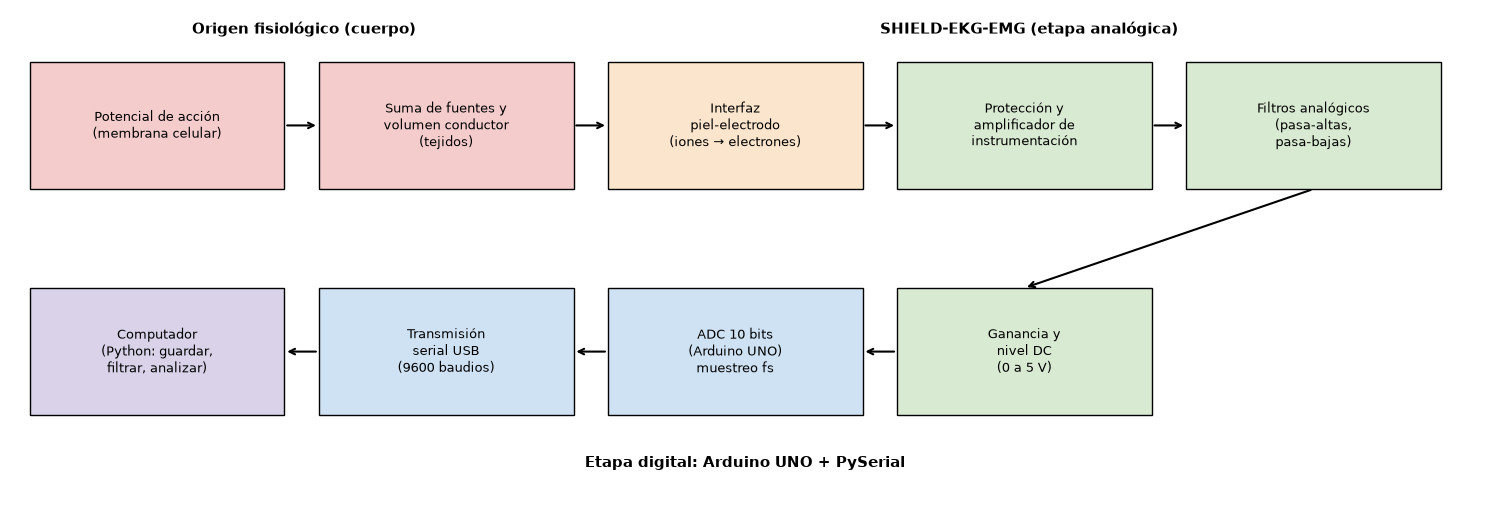

In [2]:
# Esquema de bloques de la cadena de registro (hecho con matplotlib)
etapas = [
    ("Potencial de acción\n(membrana celular)", "#f4cccc"),
    ("Suma de fuentes y\nvolumen conductor\n(tejidos)", "#f4cccc"),
    ("Interfaz\npiel-electrodo\n(iones → electrones)", "#fce5cd"),
    ("Protección y\namplificador de\ninstrumentación", "#d9ead3"),
    ("Filtros analógicos\n(pasa-altas,\npasa-bajas)", "#d9ead3"),
    ("Ganancia y\nnivel DC\n(0 a 5 V)", "#d9ead3"),
    ("ADC 10 bits\n(Arduino UNO)\nmuestreo fs", "#cfe2f3"),
    ("Transmisión\nserial USB\n(9600 baudios)", "#cfe2f3"),
    ("Computador\n(Python: guardar,\nfiltrar, analizar)", "#d9d2e9"),
]

fig, ax = plt.subplots(figsize=(15, 5.2))
ax.set_xlim(0, 15)
ax.set_ylim(0, 5.2)
ax.axis("off")

ancho, alto = 2.6, 1.35
# 5 bloques arriba (izquierda a derecha) y 4 abajo (derecha a izquierda)
posiciones = [(0.2 + i * 2.95, 3.3) for i in range(5)] + [(0.2 + (4 - i) * 2.95, 0.9) for i in range(1, 5)]
for (texto, color), (x, y) in zip(etapas, posiciones):
    ax.add_patch(plt.Rectangle((x, y), ancho, alto, fc=color, ec="k"))
    ax.text(x + ancho / 2, y + alto / 2, texto, ha="center", va="center", fontsize=9.5)

flecha = dict(arrowstyle="->", lw=1.5, color="k")
for i in range(len(posiciones) - 1):
    x1, y1 = posiciones[i]
    x2, y2 = posiciones[i + 1]
    if y1 == y2 and x2 > x1:    # fila de arriba
        ax.annotate("", xy=(x2, y2 + alto / 2), xytext=(x1 + ancho, y1 + alto / 2), arrowprops=flecha)
    elif y1 == y2:              # fila de abajo
        ax.annotate("", xy=(x2 + ancho, y2 + alto / 2), xytext=(x1, y1 + alto / 2), arrowprops=flecha)
    else:                       # bajada del bloque 5 al 6
        ax.annotate("", xy=(x2 + ancho / 2, y2 + alto), xytext=(x1 + ancho / 2, y1), arrowprops=flecha)

# llaves para separar lo fisiológico, el módulo analógico y la parte digital
ax.text(3.0, 4.95, "Origen fisiológico (cuerpo)", ha="center", fontsize=10.5, weight="bold")
ax.text(10.4, 4.95, "SHIELD-EKG-EMG (etapa analógica)", ha="center", fontsize=10.5, weight="bold")
ax.text(7.5, 0.35, "Etapa digital: Arduino UNO + PySerial", ha="center", fontsize=10.5, weight="bold")
plt.tight_layout()
plt.show()

**Figura 1.** Etapas del registro de biopotenciales, desde que se genera el potencial de acción hasta que los datos quedan guardados en el computador. Rojo: parte fisiológica; naranja: interfaz piel-electrodo; verde: acondicionamiento analógico del SHIELD-EKG-EMG; azul: digitalización y transmisión; morado: procesamiento en el PC.

**Etapas y componentes del equipo** [4]:

1. **Generación.** El potencial de acción nace en la membrana de las células cardíacas o de las fibras musculares; es la fuente de la información.
2. **Volumen conductor.** Músculo, grasa y piel conducen la señal, pero también la atenúan y la filtran espacialmente. Por eso la amplitud y la forma cambian según dónde pongamos los electrodos (la derivación).
3. **Interfaz piel-electrodo.** Aquí la corriente iónica pasa a ser electrónica. Es la etapa más delicada (impedancia alta, potencial de media celda, artefactos de movimiento) y la discutimos en el punto 5.3.
4. **Protección y amplificador de instrumentación.** Amplifica la *diferencia* entre dos electrodos y rechaza lo que les llega igual a ambos, como la interferencia de la red, gracias a su alta razón de rechazo de modo común (CMRR) y a su alta impedancia de entrada. El tercer electrodo (referencia o pierna derecha) fija el potencial del cuerpo respecto al circuito. Los equipos clínicos, además, aíslan eléctricamente al paciente.
5. **Filtros analógicos.** El pasa-altas elimina la componente DC y la deriva lenta de los electrodos; el pasa-bajas limita el ancho de banda antes de muestrear (*antialiasing*).
6. **Ganancia y nivel DC.** La señal, de milivoltios, se amplifica para aprovechar el rango del convertidor análogo-digital (ADC) y se desplaza para que quede entre 0 y 5 V. En nuestros datos las dos señales quedaron centradas cerca de 2.5 V.
7. **Conversión análoga-digital.** El ADC de 10 bits del Arduino UNO entrega valores de 0 a 1023 para 0 a 5 V. En esta etapa quedan definidas la frecuencia de muestreo y la resolución en amplitud.
8. **Transmisión.** Cada muestra viaja como texto por el puerto serial (USB) a 9600 baudios.
9. **Computador.** "PySerial.py" lee 5000 muestras, las pasa a voltios y las guarda; en este notebook las filtramos y analizamos.

## 5.2 Fuentes de ruido en el registro de biopotenciales

Por **ruido** entendemos cualquier componente de la señal registrada que no viene del fenómeno que queremos medir. Para decidir si una fuente es estática o variante en el tiempo usamos este criterio: es **estática** si su frecuencia, amplitud o estadística casi no cambian durante el registro, de modo que un filtro fijo la puede quitar; es **variante** si aparece, desaparece o cambia según lo que hagan el sujeto o el entorno, y por eso cuesta más eliminarla [4].

In [3]:
fuentes_ruido = pd.DataFrame([
    ["Interferencia de la red eléctrica (60 Hz en Colombia y armónicos)",
     "Acople capacitivo e inductivo de cables y equipos cercanos con el cuerpo y los cables de los electrodos",
     "Estática (frecuencia fija; la amplitud cambia si se mueven los cables)",
     "Amplificador diferencial con alto CMRR, electrodo de referencia, cables cortos, trenzados o apantallados, alejarse de equipos, filtro notch digital"],
    ["Deriva de la línea de base",
     "Respiración, cambios lentos del potencial de los electrodos, sudor",
     "Variante (lenta, < 0.5 Hz)",
     "Reposo y respiración tranquila, preparación de la piel, filtro pasa-altas (≈0.5 Hz para monitoreo)"],
    ["Artefactos de movimiento",
     "Movimiento del electrodo respecto a la piel, estiramiento de la piel, tirones del cable",
     "Variante (aparece con el movimiento)",
     "Sujeto quieto, fijar electrodos y cables, abrasión suave de la piel, electrodos con gel; descartar los tramos afectados"],
    ["Interferencia electromiográfica en el ECG",
     "Actividad de músculos cercanos (pectorales, brazos), temblor, hablar",
     "Variante",
     "Sujeto relajado y en silencio, ubicar electrodos sobre zonas con poco músculo, filtro pasa-bajas (≈35-40 Hz para monitoreo)"],
    ['Ruido de contacto y "electrode pop"',
     "Pérdida parcial de contacto o gel seco; cambios bruscos de la impedancia",
     "Variante (impulsiva)",
     "Revisar que el electrodo esté bien pegado, cambiar electrodos secos, buena preparación de la piel"],
    ["Potencial de media celda (offset DC) de los electrodos",
     "Interfaz metal-electrolito; diferencia entre los dos electrodos",
     "Estática (casi constante, con deriva lenta)",
     "Electrodos no polarizables de Ag/AgCl, acople AC o pasa-altas antes de la ganancia alta"],
    ["Ruido térmico y electrónico del amplificador",
     "Resistencia de los electrodos y de la piel; componentes del circuito",
     "Estática (ruido aleatorio estacionario)",
     "Amplificadores de bajo ruido, limitar el ancho de banda al necesario, baja impedancia de contacto"],
    ["Ruido de cuantización y saturación del ADC",
     "Resolución finita (10 bits ≈ 4.9 mV) y rango limitado de 0 a 5 V",
     "Estática (depende del diseño); la saturación aparece cuando la señal es muy grande",
     "Ajustar la ganancia para usar el rango sin saturar, ADC de más bits"],
    ["Diafonía del ECG en el EMG (crosstalk)",
     "Actividad cardíaca que llega a electrodos de EMG en tronco o brazo; músculos vecinos",
     "Variante (cuasi periódica)",
     "Electrodos pequeños y cercanos sobre el vientre muscular, pasa-altas de 10-20 Hz para sEMG"],
], columns=["Fuente de ruido", "Origen", "¿Estática o variante?", "Estrategias de control o eliminación"])

fuentes_ruido.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"})

Fuente de ruido,Origen,¿Estática o variante?,Estrategias de control o eliminación
Interferencia de la red eléctrica (60 Hz en Colombia y armónicos),Acople capacitivo e inductivo de cables y equipos cercanos con el cuerpo y los cables de los electrodos,Estática (frecuencia fija; la amplitud cambia si se mueven los cables),"Amplificador diferencial con alto CMRR, electrodo de referencia, cables cortos, trenzados o apantallados, alejarse de equipos, filtro notch digital"
Deriva de la línea de base,"Respiración, cambios lentos del potencial de los electrodos, sudor","Variante (lenta, < 0.5 Hz)","Reposo y respiración tranquila, preparación de la piel, filtro pasa-altas (≈0.5 Hz para monitoreo)"
Artefactos de movimiento,"Movimiento del electrodo respecto a la piel, estiramiento de la piel, tirones del cable",Variante (aparece con el movimiento),"Sujeto quieto, fijar electrodos y cables, abrasión suave de la piel, electrodos con gel; descartar los tramos afectados"
Interferencia electromiográfica en el ECG,"Actividad de músculos cercanos (pectorales, brazos), temblor, hablar",Variante,"Sujeto relajado y en silencio, ubicar electrodos sobre zonas con poco músculo, filtro pasa-bajas (≈35-40 Hz para monitoreo)"
"Ruido de contacto y ""electrode pop""",Pérdida parcial de contacto o gel seco; cambios bruscos de la impedancia,Variante (impulsiva),"Revisar que el electrodo esté bien pegado, cambiar electrodos secos, buena preparación de la piel"
Potencial de media celda (offset DC) de los electrodos,Interfaz metal-electrolito; diferencia entre los dos electrodos,"Estática (casi constante, con deriva lenta)","Electrodos no polarizables de Ag/AgCl, acople AC o pasa-altas antes de la ganancia alta"
Ruido térmico y electrónico del amplificador,Resistencia de los electrodos y de la piel; componentes del circuito,Estática (ruido aleatorio estacionario),"Amplificadores de bajo ruido, limitar el ancho de banda al necesario, baja impedancia de contacto"
Ruido de cuantización y saturación del ADC,Resolución finita (10 bits ≈ 4.9 mV) y rango limitado de 0 a 5 V,Estática (depende del diseño); la saturación aparece cuando la señal es muy grande,"Ajustar la ganancia para usar el rango sin saturar, ADC de más bits"
Diafonía del ECG en el EMG (crosstalk),Actividad cardíaca que llega a electrodos de EMG en tronco o brazo; músculos vecinos,Variante (cuasi periódica),"Electrodos pequeños y cercanos sobre el vientre muscular, pasa-altas de 10-20 Hz para sEMG"


**Tabla 1.** Principales fuentes de ruido en el registro de biopotenciales, si son estáticas o variantes en el tiempo y cómo se controlan [4], [5].

Las fuentes estáticas (red eléctrica, potencial de media celda, ruido electrónico y de cuantización) tienen un comportamiento conocido y se atacan desde el diseño del equipo: CMRR, filtros fijos, resolución. Las variantes (deriva de la línea de base, movimiento, EMG, mal contacto, diafonía) dependen sobre todo del sujeto y de la preparación. Muchas comparten banda con la señal, así que los filtros no las quitan del todo y lo mejor es evitarlas desde la adquisición.

En la práctica lo vimos: cuando hablábamos o nos movíamos, la señal se llenaba de ruido, que corresponde a la interferencia muscular y a los artefactos de movimiento de la tabla. Por eso tomamos el ECG en reposo y en silencio. La interferencia de 60 Hz apareció en el sEMG (doblada por el muestreo) pero no se notó en el ECG, donde el problema principal fue la **saturación** del ADC en los picos R.

## 5.3 Acoplamiento piel-electrodo

**¿Cuál es la problemática?** En el electrodo se encuentran iones, del lado del cuerpo, y electrones, del lado del cable, así que ahí ocurre una reacción de oxidación-reducción. En la interfaz metal-electrolito se forma una doble capa de carga que produce un **potencial de media celda**, un voltaje DC que puede llegar a cientos de milivoltios, mucho más que el propio ECG [4]. A eso se suma el estrato córneo, la capa externa de la piel, seca y formada por células muertas, que tiene una **impedancia alta** y se modela como resistencias en paralelo con capacitancias [4]. De ahí salen varios problemas:

- **Impedancia alta y desbalanceada.** Si los dos electrodos tienen impedancias distintas, parte de la interferencia de modo común (60 Hz) se vuelve diferencial y el amplificador ya no la puede rechazar, por bueno que sea su CMRR [4].
- **Potencial de media celda y su deriva.** Si los electrodos no tienen el mismo potencial aparece un offset DC, y si ese potencial cambia (sudor, gel que se seca, presión) aparece deriva de la línea de base.
- **Artefactos de movimiento.** Al estirar o presionar la piel cambian el potencial entre sus capas y la distribución de cargas en el gel. El resultado son oscilaciones lentas y grandes, justo en la banda del ECG [4].
- **Cambios durante el registro.** El gel se seca, la piel suda y la impedancia no se queda quieta.

**Estrategias para mejorarlo** [4], [5]:

- Limpiar la piel con alcohol para quitar grasa y sudor, como hicimos en la práctica. A veces también se depila y se hace una abrasión suave, que reduce bastante los artefactos de movimiento.
- Usar electrodos **no polarizables de Ag/AgCl con gel electrolítico**, cuyo potencial de media celda es bajo y estable.
- Esperar unos minutos después de pegar los electrodos para que el gel humedezca la piel y la impedancia se estabilice.
- Fijar electrodos y cables para que no se muevan ni tiren, y pedirle al sujeto que se quede quieto y relajado.
- En sEMG, poner los electrodos sobre el vientre del músculo, alineados con las fibras, y la referencia sobre una zona eléctricamente inactiva, como el hueso de la muñeca [5].
- Usar electrodos activos (con un preamplificador en el mismo electrodo) o amplificadores con impedancia de entrada muy alta, para que la impedancia de contacto pese menos.

**¿Por qué es la etapa más crítica en sEMG, electroencefalograma (EEG) y ECG?** Porque es la primera de la cadena: lo que entre mal ahí se amplifica junto con la señal. Las señales de superficie son muy pequeñas (µV en EEG, de µV a mV en sEMG, cerca de 1 mV en ECG) y comparten banda con los artefactos de movimiento y la deriva, de modo que después ningún filtro las separa por completo. Además, un mal contacto arruina el rechazo de la interferencia de la red aunque el amplificador sea muy bueno, porque el desbalance de impedancias convierte el ruido común en diferencial [4]. Por eso, en estas señales, la calidad del registro depende más de cómo se prepara la piel y se pone el electrodo que del resto del equipo.

## Registros de la práctica (procedimientos 4.1 y 4.2)

### Montaje y condiciones del registro

| | ECG (procedimiento 4.1) | sEMG (procedimiento 4.2) |
|---|---|---|
| Equipo | SHIELD-EKG-EMG (Olimex) sobre Arduino UNO, entrada A0 | El mismo |
| Ubicación de electrodos | Triángulo de Einthoven (Figura 2 de la guía) | Referencia en la muñeca, centrada; los otros dos electrodos juntos sobre el pronador y el flexor del antebrazo, donde más se marcaba el músculo |
| Preparación de la piel | Limpieza con alcohol | Limpieza con alcohol |
| Condición | Reposo, sin hablar | Contracciones repetidas del antebrazo y luego reposo hasta el final del registro |
| Muestras guardadas | 5000 (`numero_datos` en `PySerial.py`) | 5000 |
| Archivos | `ECG_d.txt` (datos) y `ECG_i.png` (figura) | `EMG_NASSER.txt` (datos) y `Figure_1.png` (figura), en `lab_bioseñales/EMG` |

**Tabla 2.** Condiciones de los registros. No tomamos fotos del montaje.

### Carga y preparación de las señales

Antes del punto 5.4 necesitamos tres cosas: el eje de tiempo, el ECG filtrado para los detectores y una forma de ver las contracciones en el sEMG. La frecuencia de muestreo (fs) no quedó registrada; por el "delay(10)" del Arduino debía ser algo menor que 100 Hz, y la estimamos con el pico de la red de 60 Hz, que en el espectro del sEMG aparece "doblado" (aliasing) en fs − 60 Hz. El ECG lo filtramos con un pasa-banda de 0.5 a 35 Hz, que quita el nivel DC y la deriva sin tocar el QRS [4]. Al sEMG le aplicamos el procesamiento básico: pasa-altas de 10 Hz, rectificación y un promedio móvil de 250 ms como envolvente; las partes en que la envolvente supera el reposo del final (media + 3 desviaciones estándar) durante al menos medio segundo las contamos como contracciones.

In [4]:
ecg_v = np.loadtxt(ARCHIVO_ECG)    # voltios a la entrada del ADC
emg_v = np.loadtxt(ARCHIVO_EMG)

# fs a partir del pico de 60 Hz doblado, en ciclos por muestra
espectro = np.abs(np.fft.rfft(emg_v - emg_v.mean()))
f_norm = np.fft.rfftfreq(len(emg_v))
zona = (f_norm > 0.30) & (f_norm < 0.48)
f_pico = f_norm[zona][np.argmax(espectro[zona])]
FS = round(60 / (1 - f_pico), 1)
t_ecg = np.arange(len(ecg_v)) / FS
t_emg = np.arange(len(emg_v)) / FS
print(f"fs estimada: {FS} Hz  ->  {len(ecg_v)} muestras = {t_ecg[-1]:.1f} s")
print("Muestras del ECG saturadas en 5 V:", np.sum(ecg_v >= 5.0))

# ECG filtrado para los detectores
b_ecg, a_ecg = signal.butter(3, [0.5, 35], btype="bandpass", fs=FS)
ecg_filt = signal.filtfilt(b_ecg, a_ecg, ecg_v)

# sEMG: pasa-altas, rectificación y envolvente
b_emg, a_emg = signal.butter(4, 10, btype="highpass", fs=FS)
emg_rect = np.abs(signal.filtfilt(b_emg, a_emg, emg_v))
ventana = int(0.25 * FS)
envolvente = np.convolve(emg_rect, np.ones(ventana) / ventana, mode="same")

reposo = t_emg > 32    # al final del registro no hay contracciones
umbral = envolvente[reposo].mean() + 3 * envolvente[reposo].std()
cambios = np.diff(np.concatenate(([0], (envolvente > umbral).astype(int), [0])))
contracciones = []
for i0, i1 in zip(np.where(cambios == 1)[0], np.where(cambios == -1)[0]):
    if (i1 - i0) / FS >= 0.5:
        contracciones.append((i0 / FS, i1 / FS))
duraciones = [fin - inicio for inicio, fin in contracciones]
print(f"Contracciones en el sEMG: {len(contracciones)}, de {min(duraciones):.1f} a {max(duraciones):.1f} s")

fs estimada: 97.4 Hz  ->  5000 muestras = 51.3 s
Muestras del ECG saturadas en 5 V: 101
Contracciones en el sEMG: 7, de 1.0 a 4.2 s


Graficamos en una sola figura las dos señales: el ECG completo y un acercamiento antes y después de filtrar, y el sEMG con su envolvente y las contracciones encontradas.

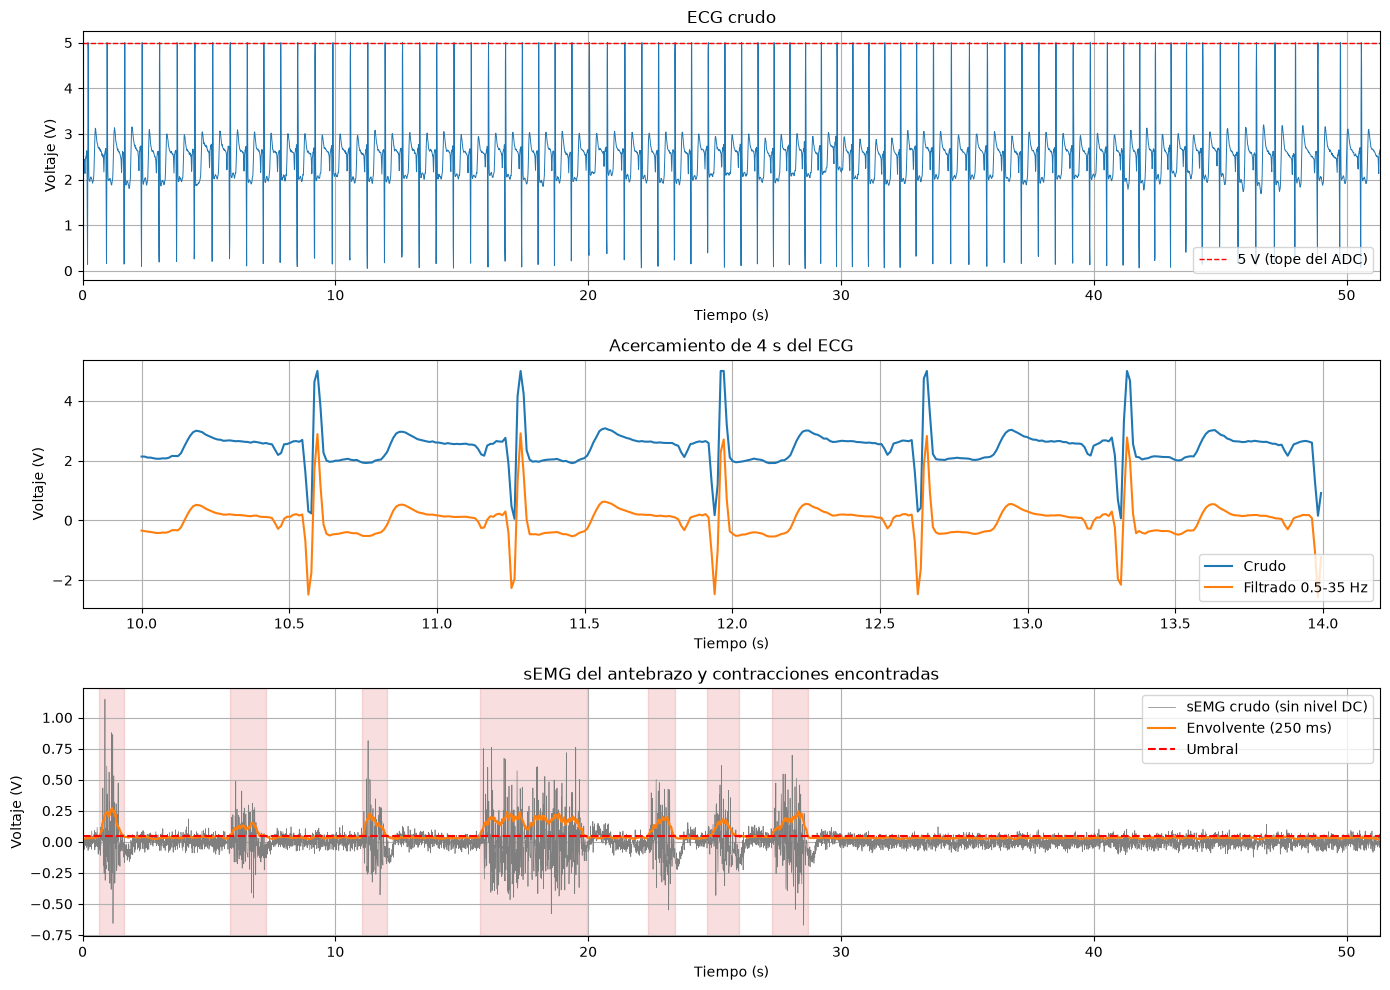

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(14, 10))

ax[0].plot(t_ecg, ecg_v, lw=0.7)
ax[0].axhline(5.0, color="r", ls="--", lw=1, label="5 V (tope del ADC)")
ax[0].set_title("ECG crudo")
ax[0].set_ylabel("Voltaje (V)")
ax[0].set_xlim(0, t_ecg[-1])
ax[0].legend(loc="lower right")

tramo = (t_ecg >= 10) & (t_ecg <= 14)
ax[1].plot(t_ecg[tramo], ecg_v[tramo], label="Crudo")
ax[1].plot(t_ecg[tramo], ecg_filt[tramo], label="Filtrado 0.5-35 Hz")
ax[1].set_title("Acercamiento de 4 s del ECG")
ax[1].set_ylabel("Voltaje (V)")
ax[1].legend(loc="lower right")

ax[2].plot(t_emg, emg_v - emg_v.mean(), lw=0.5, color="tab:gray", label="sEMG crudo (sin nivel DC)")
ax[2].plot(t_emg, envolvente, color="tab:orange", lw=1.5, label="Envolvente (250 ms)")
ax[2].axhline(umbral, color="r", ls="--", label="Umbral")
for inicio, fin in contracciones:
    ax[2].axvspan(inicio, fin, color="tab:red", alpha=0.15)
ax[2].set_title("sEMG del antebrazo y contracciones encontradas")
ax[2].set_ylabel("Voltaje (V)")
ax[2].set_xlim(0, t_emg[-1])
ax[2].legend(loc="upper right")
for a in ax:
    a.set_xlabel("Tiempo (s)")
plt.tight_layout()
plt.show()

**Figura 2.** Arriba: ECG crudo; la línea roja es el tope del ADC. Centro: acercamiento de 4 s del ECG crudo y filtrado. Abajo: sEMG sin el nivel DC, su envolvente y el umbral; en rojo, las contracciones encontradas.

En el ECG se reconocen el QRS y la onda T, pero todos los picos R llegan a 5 V y quedan planos porque la ganancia del shield era muy alta. Para contar latidos no es grave, ya que el R sigue siendo lo más alto de cada latido, y el filtro centra la señal sin cambiar su forma. En el sEMG la envolvente separa siete contracciones en los primeros 29 s: seis de alrededor de un segundo y una de unos 4 s. Después la señal queda en reposo hasta el final. Con una fs tan baja solo vemos una parte del contenido del sEMG [5], pero basta para saber cuándo se activa el músculo.

## 5.4 Análisis de la variabilidad de la frecuencia cardíaca (HRV)

La HRV describe cuánto cambia el tiempo entre latidos consecutivos, los llamados intervalos RR. Aunque en reposo el corazón parece latir regular, esos intervalos cambian latido a latido por la acción del sistema nervioso autónomo y de la respiración [6]. Para calcularla primero hay que ubicar bien los picos R.

### 5.4.1 Detección de picos R con NeuroKit y con Detectors

Para saber qué algoritmo detecta mejor necesitamos una referencia de dónde están los picos R. Como todos los R llegan a 5 V, los buscamos en la señal cruda como los máximos por encima de 4.15 V separados al menos 0.3 s, y revisamos a ojo en la Figura 2 (arriba) que no faltara ni sobrara ninguno.

In [6]:
picos_ref, _ = signal.find_peaks(ecg_v, height=4.15, distance=int(0.3 * FS))
print("Picos R de referencia:", len(picos_ref))

Picos R de referencia: 75


Luego aplicamos los detectores al ECG filtrado. De NeuroKit usamos "ecg_peaks" [1]; de Detectors probamos dos de sus algoritmos: el clásico de Pan-Tompkins [7] y el de dos promedios móviles de Elgendi [8].

In [7]:
detectores = Detectors(FS)
picos = {}

_, info = nk.ecg_peaks(ecg_filt, sampling_rate=FS)
picos["NeuroKit"] = np.array(info["ECG_R_Peaks"])
picos["Pan-Tompkins"] = np.array(detectores.pan_tompkins_detector(ecg_filt))
picos["Elgendi"] = np.array(detectores.two_average_detector(ecg_filt))

for nombre in picos:
    print(nombre, "->", len(picos[nombre]), "picos")

NeuroKit -> 75 picos
Pan-Tompkins -> 75 picos
Elgendi -> 75 picos


Para comparar, contamos como acierto un pico que quede a menos de 100 ms de un R de referencia. También medimos qué tan lejos queda cada pico del R en promedio, porque un error en la posición del pico cambia los intervalos RR y por lo tanto la HRV.

In [8]:
tolerancia = int(0.1 * FS)   # 100 ms en muestras
filas = []
for nombre, p in picos.items():
    aciertos = 0
    errores = []
    for r in picos_ref:
        distancia = np.min(np.abs(p - r))
        if distancia <= tolerancia:
            aciertos += 1
            errores.append(distancia / FS * 1000)
    filas.append([nombre, len(p), aciertos, len(p) - aciertos, len(picos_ref) - aciertos, np.mean(errores)])

comparacion = pd.DataFrame(filas, columns=["Detector", "Picos", "Aciertos", "Picos de más", "R no detectados", "Distancia media al R (ms)"])
comparacion.round(1)

,Detector,Picos,Aciertos,Picos de más,R no detectados,Distancia media al R (ms)
0,NeuroKit,75,74,1,1,2.4
1,Pan-Tompkins,75,75,0,0,66.0
2,Elgendi,75,75,0,0,9.6


**Tabla 3.** Comparación de los detectores con los picos R de referencia.

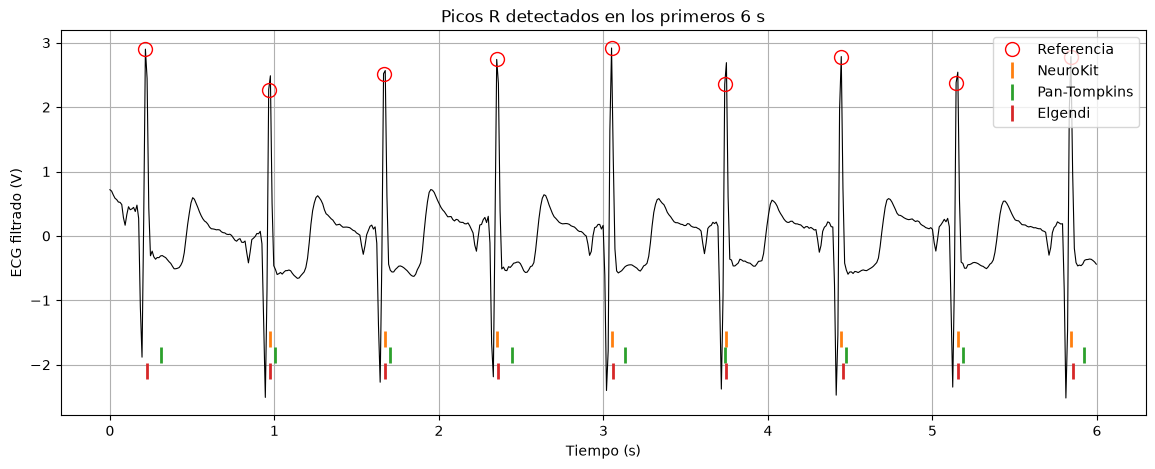

In [9]:
# inicio del registro con las marcas de cada detector
tramo = t_ecg <= 6
plt.figure(figsize=(14, 5))
plt.plot(t_ecg[tramo], ecg_filt[tramo], color="k", lw=0.8)
ref = picos_ref[picos_ref < tramo.sum()]
plt.plot(t_ecg[ref], ecg_filt[ref], "o", mfc="none", mec="r", ms=10, label="Referencia")
for i, nombre in enumerate(picos):
    p = picos[nombre][picos[nombre] < tramo.sum()]
    plt.plot(t_ecg[p], np.full(len(p), -1.6 - 0.25 * i), "|", ms=12, mew=2, label=nombre)
plt.xlabel("Tiempo (s)")
plt.ylabel("ECG filtrado (V)")
plt.title("Picos R detectados en los primeros 6 s")
plt.legend(loc="upper right")
plt.show()

**Figura 3.** ECG filtrado de los primeros 6 s. Los círculos rojos son los R de referencia y cada fila de marcas, debajo de la señal, corresponde a un detector.

#### ¿Cuál algoritmo detecta mejor los picos R?

Los tres encuentran casi todos los latidos, porque el ECG es limpio. NeuroKit no detecta el primer R, que está casi al inicio del registro (Figura 3), y pone un pico de más al final. Pan-Tompkins y Elgendi encuentran todos los R sin picos de más, pero Pan-Tompkins marca los picos bastante más lejos del R que los demás (Tabla 3), y ese corrimiento altera los intervalos RR. NeuroKit es el que queda más cerca del R, pero falla en los bordes del registro. Por eso, en nuestro registro, el que mejor detecta los picos R es el **detector de dos promedios de Elgendi**, de Detectors, y con él calculamos la HRV.

### 5.4.2 Cálculo de la HRV a partir de los picos R

Con los picos de Elgendi calculamos los intervalos RR en milisegundos y la frecuencia cardíaca (FC) de cada latido. Para ver cómo cambian a lo largo del registro hacemos el tacograma, que es la gráfica de cada intervalo RR contra el tiempo.

Intervalos RR: 74
RR medio: 681 ms;  mínimo 616 ms y máximo 893 ms
FC media: 88.6 lpm


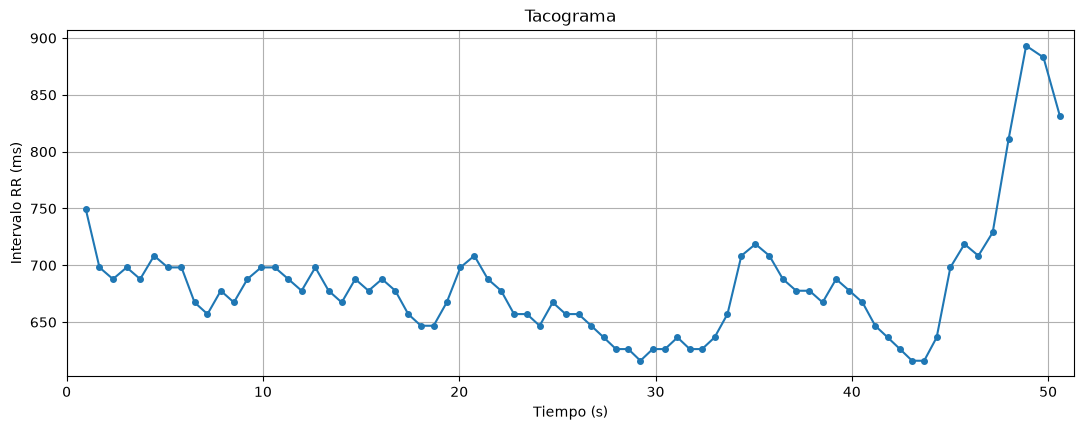

In [10]:
picos_hrv = picos["Elgendi"]
rr_ms = np.diff(picos_hrv) / FS * 1000   # intervalos RR en ms
t_rr = picos_hrv[1:] / FS
fc = 60000 / rr_ms                        # frecuencia cardíaca en lpm

print("Intervalos RR:", len(rr_ms))
print(f"RR medio: {rr_ms.mean():.0f} ms;  mínimo {rr_ms.min():.0f} ms y máximo {rr_ms.max():.0f} ms")
print(f"FC media: {fc.mean():.1f} lpm")

plt.figure(figsize=(13, 4.5))
plt.plot(t_rr, rr_ms, "o-", ms=4)
plt.xlabel("Tiempo (s)")
plt.ylabel("Intervalo RR (ms)")
plt.title("Tacograma")
plt.xlim(0, t_ecg[-1])
plt.show()

**Figura 4.** Tacograma: cada intervalo RR contra el tiempo en que termina.

Los intervalos RR no son constantes: hay oscilaciones de pocos latidos, que pueden venir de la respiración, y cambios más lentos. Hacia el final del registro los intervalos se alargan, es decir, la FC baja.

### 5.4.3 Características en el dominio del tiempo con "get_time_domain_features"

La función "get_time_domain_features" de "hrvanalysis" recibe la lista de intervalos RR en milisegundos y devuelve un diccionario con los índices de HRV en el dominio del tiempo [3]. Los más usados son el SDNN, la desviación estándar de los intervalos, que resume la variabilidad total; el RMSSD, que mide cuánto cambia un intervalo respecto al siguiente; y el pNN50, el porcentaje de intervalos seguidos que difieren en más de 50 ms [6].

In [11]:
indices = get_time_domain_features(list(rr_ms))

tabla_hrv = pd.DataFrame({"Índice": list(indices.keys()), "Valor": [float(v) for v in indices.values()]})
tabla_hrv.round(2)

,Índice,Valor
0,mean_nni,680.67
1,sdnn,51.93
2,sdsd,22.96
3,nni_50,6.00
4,pnni_50,8.22
5,nni_20,26.00
6,pnni_20,35.62
7,rmssd,22.99
8,median_nni,677.62
9,range_nni,277.21


**Tabla 4.** Índices de HRV en el dominio del tiempo que entrega "get_time_domain_features". Los tiempos están en ms y las FC en latidos por minuto (lpm).

#### Interpretación

La FC media quedó dentro del rango normal, aunque algo alta para un reposo; tomamos el registro poco después de movernos y poner los electrodos. El SDNN está cerca de lo que se reporta para adultos sanos, mientras que el RMSSD y el pNN50 quedan en la parte baja [9], lo que cuadra con una FC algo alta. De todas formas, estos valores solo sirven para ilustrar el procedimiento: el registro dura menos de un minuto, cuando se recomiendan al menos 5 min, y con nuestra fs cada intervalo RR se mide en pasos de unos 10 ms [6].

## 5.5 Aplicaciones clínicas del ECG y del EMG

Para este punto consultamos tres aplicaciones clínicas de cada señal y las organizamos en una tabla con el tipo de registro y el procesamiento que usa cada una.

In [12]:
aplicaciones = pd.DataFrame([
    ["ECG", "Monitoreo ambulatorio (Holter) para arritmias y fibrilación auricular",
     "ECG continuo de 24-48 h (o más) con 2-3 canales y electrodos en el tórax, mientras el paciente hace su vida normal",
     "Filtrado, detección automática de QRS, cálculo de RR y FC, clasificación de latidos (normales, ectópicos), detección de pausas y episodios de FA; revisión final por un especialista [10]"],
    ["ECG", "Diagnóstico del infarto agudo de miocardio",
     "ECG de reposo de 12 derivaciones (≈ 10 s), con electrodos en extremidades y precordiales",
     "Filtro pasa-altas de baja frecuencia (≈ 0.05 Hz) para no deformar el segmento ST; medición de la elevación o depresión del ST en el punto J, ondas Q y cambios de la onda T, comparando derivaciones contiguas [11]"],
    ["ECG", "Prueba de esfuerzo para enfermedad coronaria",
     "ECG de 12 derivaciones durante ejercicio progresivo en banda o bicicleta y en la recuperación",
     "Reducción de artefactos de movimiento y de EMG, promediado de latidos (latido mediano) para medir el desnivel del ST, seguimiento de FC y arritmias inducidas [12]"],
    ["EMG", "Diagnóstico de enfermedades neuromusculares (neuropatías, miopatías, enfermedades de motoneurona)",
     "EMG con aguja (invasivo) en varios músculos, en reposo y con contracción voluntaria creciente",
     "Gran ancho de banda; análisis de actividad espontánea en reposo (fibrilaciones, ondas positivas), forma, duración y amplitud de los potenciales de unidad motora y patrón de reclutamiento [13]"],
    ["EMG", "Control de prótesis mioeléctricas de miembro superior",
     "sEMG multicanal con electrodos sobre los músculos del muñón",
     "Segmentación en ventanas cortas, extracción de características en el tiempo (valor absoluto medio, cruces por cero, longitud de onda, etc.) y clasificación (por ejemplo, análisis discriminante lineal o LDA) en tiempo real para decidir el movimiento de la prótesis [14]"],
    ["EMG", "Evaluación de fatiga muscular en rehabilitación, biomecánica y deporte",
     "sEMG bipolar sobre el vientre muscular durante contracciones sostenidas o tareas repetidas",
     "Amplitud (valor cuadrático medio o RMS, envolvente) y análisis espectral: con la fatiga la frecuencia media y la mediana bajan y la amplitud tiende a subir [15], [5]"],
], columns=["Señal", "Aplicación clínica", "Tipo de registro", "Procesamiento"])
aplicaciones.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"})

Señal,Aplicación clínica,Tipo de registro,Procesamiento
ECG,Monitoreo ambulatorio (Holter) para arritmias y fibrilación auricular,"ECG continuo de 24-48 h (o más) con 2-3 canales y electrodos en el tórax, mientras el paciente hace su vida normal","Filtrado, detección automática de QRS, cálculo de RR y FC, clasificación de latidos (normales, ectópicos), detección de pausas y episodios de FA; revisión final por un especialista [10]"
ECG,Diagnóstico del infarto agudo de miocardio,"ECG de reposo de 12 derivaciones (≈ 10 s), con electrodos en extremidades y precordiales","Filtro pasa-altas de baja frecuencia (≈ 0.05 Hz) para no deformar el segmento ST; medición de la elevación o depresión del ST en el punto J, ondas Q y cambios de la onda T, comparando derivaciones contiguas [11]"
ECG,Prueba de esfuerzo para enfermedad coronaria,ECG de 12 derivaciones durante ejercicio progresivo en banda o bicicleta y en la recuperación,"Reducción de artefactos de movimiento y de EMG, promediado de latidos (latido mediano) para medir el desnivel del ST, seguimiento de FC y arritmias inducidas [12]"
EMG,"Diagnóstico de enfermedades neuromusculares (neuropatías, miopatías, enfermedades de motoneurona)","EMG con aguja (invasivo) en varios músculos, en reposo y con contracción voluntaria creciente","Gran ancho de banda; análisis de actividad espontánea en reposo (fibrilaciones, ondas positivas), forma, duración y amplitud de los potenciales de unidad motora y patrón de reclutamiento [13]"
EMG,Control de prótesis mioeléctricas de miembro superior,sEMG multicanal con electrodos sobre los músculos del muñón,"Segmentación en ventanas cortas, extracción de características en el tiempo (valor absoluto medio, cruces por cero, longitud de onda, etc.) y clasificación (por ejemplo, análisis discriminante lineal o LDA) en tiempo real para decidir el movimiento de la prótesis [14]"
EMG,"Evaluación de fatiga muscular en rehabilitación, biomecánica y deporte",sEMG bipolar sobre el vientre muscular durante contracciones sostenidas o tareas repetidas,"Amplitud (valor cuadrático medio o RMS, envolvente) y análisis espectral: con la fatiga la frecuencia media y la mediana bajan y la amplitud tiende a subir [15], [5]"


**Tabla 5.** Tres aplicaciones clínicas del ECG y tres del EMG, con el tipo de registro y el procesamiento de cada una.

Lo que hicimos en la práctica se parece a un Holter muy simplificado (un canal, detección de QRS y HRV), y el procesamiento del sEMG (rectificar, sacar la envolvente y buscar las contracciones) es el primer paso de las aplicaciones de prótesis y de fatiga.

## 5.6 Conclusiones y referencias

### Conclusiones

1. **El equipo permite registrar ECG y sEMG, pero su configuración limita lo que se puede analizar.** La ganancia alta saturó los picos R y la fs tan baja deja muy pocos puntos por latido y solo una parte del contenido del sEMG. Para una próxima práctica convendría bajar la ganancia, muestrear más rápido y dejar anotada la fs.
2. **Detectar un latido no es lo mismo que ubicarlo bien.** Todos los algoritmos encontraron casi todos los picos R, pero solo el de Elgendi los encontró todos y los ubicó con precisión. Cuando lo que interesa es la HRV, la precisión en la posición del pico pesa tanto como no perder latidos.
3. **La HRV que obtuvimos es solo ilustrativa.** El procedimiento funciona y los valores son razonables para una persona sana, pero el registro es demasiado corto y con poca resolución temporal para sacar conclusiones sobre el sistema nervioso autónomo.
4. **En el sEMG la amplitud basta para saber cuándo se activa el músculo.** Con un procesamiento sencillo (filtrar, rectificar y sacar la envolvente) las contracciones se distinguen claramente del reposo.
5. **La calidad del registro se decide en la piel y en el sujeto.** Hablar o moverse llenaba la señal de ruido, y como ese ruido comparte banda con la señal, es mejor prevenirlo con una buena preparación de la piel y quedándose quieto que intentar filtrarlo después.

### Referencias

[1] D. Makowski, T. Pham, Z. J. Lau, J. C. Brammer, F. Lespinasse, H. Pham, C. Schölzel y S. H. A. Chen, "NeuroKit2: A Python toolbox for neurophysiological signal processing," *Behavior Research Methods*, vol. 53, no. 4, pp. 1689–1696, 2021. doi: 10.3758/s13428-020-01516-y.

[2] L. Howell y B. Porr, "py-ecg-detectors: Popular ECG R peak detectors written in Python" (software, v1.3.5), GitHub. Disponible: https://github.com/berndporr/py-ecg-detectors

[3] R. Champseix, "hrv-analysis: package for heart rate variability analysis in Python" (software, v1.0.x), Aura Healthcare, GitHub. Disponible: https://github.com/Aura-healthcare/hrv-analysis

[4] J. G. Webster, Ed., *Medical Instrumentation: Application and Design*, 4th ed. Hoboken, NJ, EE. UU.: John Wiley & Sons, 2009.

[5] C. J. De Luca, "The use of surface electromyography in biomechanics," *Journal of Applied Biomechanics*, vol. 13, no. 2, pp. 135–163, 1997. doi: 10.1123/jab.13.2.135.

[6] Task Force of the European Society of Cardiology and the North American Society of Pacing and Electrophysiology, "Heart rate variability: Standards of measurement, physiological interpretation, and clinical use," *Circulation*, vol. 93, no. 5, pp. 1043–1065, 1996. doi: 10.1161/01.CIR.93.5.1043.

[7] J. Pan y W. J. Tompkins, "A real-time QRS detection algorithm," *IEEE Transactions on Biomedical Engineering*, vol. BME-32, no. 3, pp. 230–236, 1985. doi: 10.1109/TBME.1985.325532.

[8] M. Elgendi, M. Jonkman y F. De Boer, "Frequency bands effects on QRS detection," en *Proc. 3rd Int. Conf. on Bio-inspired Systems and Signal Processing (BIOSIGNALS 2010)*, 2010, pp. 428–431. doi: 10.5220/0002742704280431.

[9] D. Nunan, G. R. H. Sandercock y D. A. Brodie, "A quantitative systematic review of normal values for short-term heart rate variability in healthy adults," *Pacing and Clinical Electrophysiology*, vol. 33, no. 11, pp. 1407–1417, 2010. doi: 10.1111/j.1540-8159.2010.02841.x.

[10] J. S. Steinberg *et al.*, "2017 ISHNE-HRS expert consensus statement on ambulatory ECG and external cardiac monitoring/telemetry," *Heart Rhythm*, vol. 14, no. 7, pp. e55–e96, 2017. doi: 10.1016/j.hrthm.2017.03.038.

[11] K. Thygesen *et al.*, "Fourth universal definition of myocardial infarction (2018)," *Circulation*, vol. 138, no. 20, pp. e618–e651, 2018. doi: 10.1161/CIR.0000000000000617.

[12] R. J. Gibbons *et al.*, "ACC/AHA 2002 guideline update for exercise testing: Summary article," *Circulation*, vol. 106, no. 14, pp. 1883–1892, 2002. doi: 10.1161/01.CIR.0000034670.06526.15.

[13] J. R. Daube y D. I. Rubin, "Needle electromyography," *Muscle & Nerve*, vol. 39, no. 2, pp. 244–270, 2009. doi: 10.1002/mus.21180.

[14] K. Englehart y B. Hudgins, "A robust, real-time control scheme for multifunction myoelectric control," *IEEE Transactions on Biomedical Engineering*, vol. 50, no. 7, pp. 848–854, 2003. doi: 10.1109/TBME.2003.813539.

[15] M. Cifrek, V. Medved, S. Tonković y S. Ostojić, "Surface EMG based muscle fatigue evaluation in biomechanics," *Clinical Biomechanics*, vol. 24, no. 4, pp. 327–340, 2009. doi: 10.1016/j.clinbiomech.2009.01.010.